# Manifold learning on handwritten digits (random projection embedding): scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/manifold/plot_lle_digits.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/manifold/plot_lle_digits.html)).

**Scenario:** the bundled digits (`load_digits(n_class=6)`, 1083 x 64) embedded in two dimensions; this family
owns the example's `"Random projection embedding": SparseRandomProjection(n_components=2, random_state=42)` entry,
which is fitted with `fit_transform` and drawn with the example's `plot_embedding` helper.

**Adaptations:**
- Only the random projection entry is run. The other twelve embeddings (TruncatedSVD, LDA, Isomap, the LLE variants,
  MDS, RandomTreesEmbedding pipeline, SpectralEmbedding, t-SNE, NCA) belong to the decomposition, discriminant
  analysis, manifold, ensemble and neighbors families and are recorded as SKIP.
- `plot_embedding` (MinMaxScaler plus annotated scatter) is plotting code; it runs in Python on both embeddings.
- The data are copied into Moxie's `ProjectionMatrix` storage inside the Mojo cell (the estimators do not take NDArray).

**Determinism:** deterministic (`random_state=42`, single-threaded sampling); the components and the embedding
are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("random_projection/plot_lle_digits")

## 1. scikit-learn (Python reference)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import offsetbox

from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler
from sklearn.random_projection import SparseRandomProjection

digits = load_digits(n_class=6)
X, y = digits.data, digits.target
n_samples, n_features = X.shape
n_neighbors = 30


def plot_embedding(X, title, ax):
    X = MinMaxScaler().fit_transform(X)
    for digit in digits.target_names:
        ax.scatter(*X[y == digit].T, marker=f"${digit}$", s=20, color=plt.cm.Dark2(digit), alpha=0.425, zorder=2)
    shown_images = np.array([[1.0, 1.0]])  # just something big
    for i in range(X.shape[0]):
        # plot every digit on the embedding
        # show an annotation box for a group of digits
        dist = np.sum((X[i] - shown_images) ** 2, 1)
        if np.min(dist) < 4e-3:
            # don't show points that are too close
            continue
        shown_images = np.concatenate([shown_images, [X[i]]], axis=0)
        imagebox = offsetbox.AnnotationBbox(
            offsetbox.OffsetImage(digits.images[i], cmap=plt.cm.gray_r, zoom=0.6), X[i])
        imagebox.set(zorder=1)
        ax.add_artist(imagebox)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


embeddings = {
    "Random projection embedding": SparseRandomProjection(n_components=2, random_state=42),
}
projections = {}
for name, transformer in embeddings.items():
    print(f"Computing {name}...")
    projections[name] = transformer.fit_transform(X, y)
rp = embeddings["Random projection embedding"]
sk_embedding = projections["Random projection embedding"]
sk_components = rp.components_.toarray()
sk_density = rp.density_
print(sk_embedding[:3], rp.components_.nnz)
nb.share(X=X)

Computing Random projection embedding...
[[ 22.  -4.]
 [ 22. -30.]
 [ 36. -16.]] 11


## 2. Moxie (native Mojo)

In [3]:
%%mojo lle_rp
from numojo import NDArray, Shape, zeros
from moxie.random_projection import SparseRandomProjection, ProjectionMatrix
from moxie_nb_io import load, save, save_floats

def to_projection(x: NDArray[DType.float64]) raises -> ProjectionMatrix[DType.float64]:
    var values = List[Float64]()
    for k in range(x.size):
        values.append(x.unsafe_get(k))
    return ProjectionMatrix(x.shape[0], x.shape[1], values^)


def to_ndarray(m: ProjectionMatrix[DType.float64]) raises -> NDArray[DType.float64]:
    var dense = m.to_dense()
    var out = zeros[DType.float64](Shape(dense.rows, dense.cols))
    for k in range(len(dense.data)):
        out.unsafe_set(k, dense.data[k])
    return out^


def main() raises:
    var X = to_projection(load("X"))
    var transformer = SparseRandomProjection(n_components=2, random_state=42)
    var embedding = transformer.fit_transform(X)
    print("embedding:", embedding.rows, "x", embedding.cols, "| nnz:", len(transformer.components_.data))
    save("embedding", to_ndarray(embedding))
    save("components", to_ndarray(transformer.components_))
    save_floats("density", [transformer.density_])

embedding: 1083 x 2 | nnz: 11


## 3. Side by side and parity

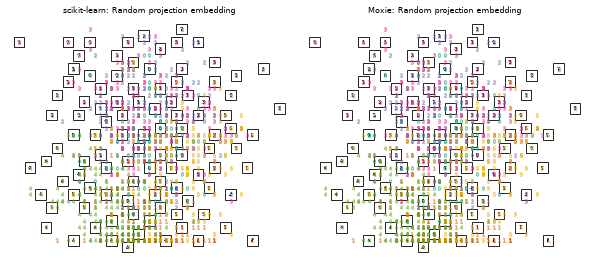

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
SparseRandomProjection.components_,PASS,"(2, 64)","(2, 64)",,,exact,0 mismatches,
density_ (auto = 1/8),PASS,(),(),,,exact,0 mismatches,
fit_transform embedding,PASS,"(1083, 2)","(1083, 2)",0,0,"rtol=1e-12, atol=1e-10",,identical +-sqrt(8/2) components; only the order of the <=64-term sums differs (SciPy sparse matmul vs native CSR loop) on integer-valued pixels
other twelve embeddings in the example,SKIP,,,,,,"owned by decomposition, discriminant_analysis, manifold, ensemble and neighbors; not part of random_projection",
NDArray input,GAP,,,,,,projections take the family-local ProjectionMatrix; data copied element-wise in the Mojo cell,


In [4]:
mx = nb.results["lle_rp"]
moxie_nb.side_by_side(sklearn=sk_embedding[:5], moxie=mx["embedding"][:5])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=60)
plot_embedding(sk_embedding, "scikit-learn: Random projection embedding", axes[0])
plot_embedding(mx["embedding"], "Moxie: Random projection embedding", axes[1])
plt.tight_layout(); plt.show()

nb.compare("SparseRandomProjection.components_", sk_components, mx["components"], exact=True)
nb.compare("density_ (auto = 1/8)", sk_density, mx["density"][0], exact=True)
nb.compare("fit_transform embedding", sk_embedding, mx["embedding"], rtol=1e-12, atol=1e-10,
           reason="identical +-sqrt(8/2) components; only the order of the <=64-term sums differs "
                  "(SciPy sparse matmul vs native CSR loop) on integer-valued pixels")
nb.note("other twelve embeddings in the example", "SKIP",
        "owned by decomposition, discriminant_analysis, manifold, ensemble and neighbors; not part of random_projection")
nb.note("NDArray input", "GAP", "projections take the family-local ProjectionMatrix; data copied element-wise in the Mojo cell")
nb.report()
nb.assert_parity()